#Fine-tuning Qwen2.5-1.5B-Instruct для классификации тональности отзывов

Задача по определению тональности русскоязычного отзыва (`negative`, `neutral`, `positive`). Просим модель возвращать JSON `{"sentiment": "..."}`.

**Что делаем:**
1. Берём `Qwen/Qwen2.5-1.5B-Instruct` — большую из двух моделей, проверенных в ДЗ 2.
2. Из `train` датасета выбираем до 200 отзывов каждого класса (до 600 примеров всего); 10% используем для валидации.
3. В качестве теста оставляем те же 20 примеров каждого класса из `test`, seed 42 (всего 60), как в ДЗ 2. Тестовые отзывы не попадают в обучение.
4. Считаем качество исходной модели **до** обучения, выполняем QLoRA fine-tuning, затем оцениваем ту же модель **после** обучения на том же test.
5. Сравниваем Accuracy, Macro-F1 и долю корректно распарсенных ответов.



Без fine-tuning у `Qwen2.5-1.5B-Instruct` на этой выборке было `Accuracy = 0.68`, `Macro-F1 = 0.66`, `parsed_share = 1.00`.

In [1]:
# Установка зависимостей без bitsandbytes: это исключает зависимость от triton.ops в Colab.
# PyTorch в Colab уже установлен, поэтому отдельно его не переустанавливаем.
!pip -q install transformers==4.48.3 peft==0.14.0 accelerate==1.2.1 datasets==3.2.0 scikit-learn pandas tqdm matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.


In [2]:
import os
import gc
import re
import json
import time
import random
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    set_seed,
)
from peft import LoraConfig, get_peft_model

SEED = 42
LABELS = ["negative", "neutral", "positive"]
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
DATASET_NAME = "ai-forever/ru-reviews-classification"
N_TEST_PER_CLASS = 20       # как в ДЗ 2: 20 * 3 = 60 тестовых отзывов
N_TRAIN_PER_CLASS = 200     # разумный объём: максимум 600 обучающих примеров
VALID_SIZE = 0.10
MAX_LENGTH = 384
MAX_NEW_TOKENS = 16
OUTPUT_DIR = "/content/qwen25-sentiment-lora"

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU не обнаружен. В Colab откройте: Среда выполнения → Сменить среду выполнения → GPU, "
        "затем выполните ноутбук заново. Fine-tuning 1.5B модели на CPU здесь не предусмотрен."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

GPU: Tesla T4
PyTorch: 2.14.1+cu130
CUDA: 13.0


## 1. Данные: train и test

В исходном датасете уже есть отдельные части `train` и `test`, поэтому мы не смешиваем их. Для ускорения обучения берём сбалансированную подвыборку из train: до 200 примеров на класс. Для проверки используем те же 60 тестовых примеров (по 20 на класс, `seed=42`), что и в ДЗ 2.

In [3]:
train_ds = load_dataset(DATASET_NAME, split="train")
test_ds = load_dataset(DATASET_NAME, split="test")
train_df_all = train_ds.to_pandas()
test_df_all = test_ds.to_pandas()

required_columns = {"text", "label_text"}
for split_name, frame in [("train", train_df_all), ("test", test_df_all)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"В split={split_name} нет ожидаемых колонок: {missing}. Колонки: {list(frame.columns)}")

print("Размер train:", len(train_df_all))
print("Размер test:", len(test_df_all))
print("Метки в train:", train_df_all["label_text"].value_counts().to_dict())
print("Метки в test:", test_df_all["label_text"].value_counts().to_dict())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/111 [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/13.3M [00:00<?, ?B/s]

validation.jsonl: 0.00B [00:00, ?B/s]

test.jsonl:   0%|          | 0.00/4.45M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/15000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/15000 [00:00<?, ? examples/s]

Размер train: 45000
Размер test: 15000
Метки в train: {'positive': 15000, 'neutral': 15000, 'negative': 15000}
Метки в test: {'negative': 5000, 'positive': 5000, 'neutral': 5000}


In [4]:
# Сбалансированная обучающая подвыборка. Берём только исходный split=train.
train_parts = []
for label in LABELS:
    part = train_df_all[train_df_all["label_text"] == label]
    n_take = min(N_TRAIN_PER_CLASS, len(part))
    if n_take == 0:
        raise ValueError(f"В train не найдено примеров класса {label!r}")
    train_parts.append(part.sample(n=n_take, random_state=SEED))

train_sample = (
    pd.concat(train_parts, ignore_index=True)
      .sample(frac=1, random_state=SEED)
      .reset_index(drop=True)
)

# Тестовая подвыборка с тем же способом формирования, что и в ДЗ 2.
test_parts = []
for label in LABELS:
    part = test_df_all[test_df_all["label_text"] == label]
    if len(part) < N_TEST_PER_CLASS:
        raise ValueError(f"В test недостаточно примеров класса {label!r}: {len(part)}")
    test_parts.append(part.sample(n=N_TEST_PER_CLASS, random_state=SEED))

test_sample = pd.concat(test_parts, ignore_index=True).reset_index(drop=True)

# Валидация выделяется только из train-подвыборки. Test не используется при обучении.
train_data, val_data = train_test_split(
    train_sample,
    test_size=VALID_SIZE,
    random_state=SEED,
    stratify=train_sample["label_text"],
)

print("Train для обучения:", len(train_data), train_data.label_text.value_counts().to_dict())
print("Validation:", len(val_data), val_data.label_text.value_counts().to_dict())
print("Test:", len(test_sample), test_sample.label_text.value_counts().to_dict())
test_sample[["text", "label_text"]].head(5)

Train для обучения: 540 {'negative': 180, 'neutral': 180, 'positive': 180}
Validation: 60 {'negative': 20, 'neutral': 20, 'positive': 20}
Test: 60 {'negative': 20, 'neutral': 20, 'positive': 20}


,text,label_text
0,Заказ так и не пришёл! Продавец долго кормил з...,negative
1,"заказала размер M, пришла чуть ли не на нескол...",negative
2,"Жакет маленький, узок в рукавах и в груди.",negative
3,Продавец крайне недобросовестный. Бесконечное ...,negative
4,ждала заказ 90 дней он так и не пришёл.ни зака...,negative


## 2. Промпт и оценка

Формат задачи оставляем ровно таким же, как в ДЗ 2: system-инструкция описывает три класса, user-сообщение содержит отзыв, целевой ответ — один JSON-объект.

In [5]:
SYSTEM_PROMPT = (
    "Ты определяешь тональность отзыва покупателя о товаре. "
    "Возможные значения: positive, neutral, negative. "
    'Ответь строго одним JSON-объектом вида {"sentiment": "<значение>"} без пояснений.'
)


def build_messages(text: str) -> list[dict]:
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Отзыв: {text}"},
    ]


def parse_answer(generation: str):
    """Достаёт label из JSON; fallback — единственное упоминание класса."""
    match = re.search(r"\{.*?\}", generation, flags=re.S)
    if match:
        try:
            value = json.loads(match.group(0)).get("sentiment", "")
            if isinstance(value, str) and value.strip().lower() in LABELS:
                return value.strip().lower()
        except json.JSONDecodeError:
            pass
    found = [label for label in LABELS if re.search(rf"\b{label}\b", generation.lower())]
    return found[0] if len(found) == 1 else None


def evaluate(generations, references):
    preds = [parse_answer(g) for g in generations]
    # Нераспарсенный ответ — ошибка, как и в ДЗ 2.
    preds_for_metrics = [p if p is not None else "__invalid__" for p in preds]
    return {
        "accuracy": accuracy_score(references, preds_for_metrics),
        "macro_f1": f1_score(references, preds_for_metrics, labels=LABELS, average="macro", zero_division=0),
        "parsed_share": sum(p is not None for p in preds) / len(preds),
    }

assert parse_answer('{"sentiment": "negative"}') == "negative"
assert parse_answer('Ответ: {"sentiment":"Positive"}.') == "positive"
assert parse_answer("не знаю") is None
print("Парсер проверен.")

Парсер проверен.


## 3. Квантизация и загрузка токенизатора

Используем 4-битную NF4-квантизацию (QLoRA) для экономии видеопамяти. Базовые веса заморожены; обучаются небольшие LoRA-адаптеры. Для T4 используем `float16`.

In [6]:
# Используем обычную FP16-модель без 4-bit quantization и bitsandbytes.
# Для Qwen2.5-1.5B на Colab T4 это более совместимый вариант.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

print("Tokenizer:", MODEL_NAME)
print("pad_token:", tokenizer.pad_token, "| eos_token:", tokenizer.eos_token)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer: Qwen/Qwen2.5-1.5B-Instruct
pad_token: <|endoftext|> | eos_token: <|im_end|>


## 4. Качество до обучения (baseline)

Сначала прогоняем исходную `Qwen2.5-1.5B-Instruct` на фиксированном test-наборе. После этого очищаем видеопамять и отдельно загружаем модель для обучения.

In [7]:
def load_base_model():
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.float16,
        device_map="auto",
        low_cpu_mem_usage=True,
    )
    model.eval()
    model.config.use_cache = True
    return model


@torch.inference_mode()
def generate_one(model, text: str, max_new_tokens: int = MAX_NEW_TOKENS) -> str:
    inputs = tokenizer.apply_chat_template(
        build_messages(text),
        add_generation_prompt=True,
        tokenize=True,
        return_tensors="pt",
        return_dict=True,
    )
    input_device = model.get_input_embeddings().weight.device
    inputs = {k: v.to(input_device) for k, v in inputs.items()}
    output = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)


def run_inference(model, frame, description):
    generations = []
    start = time.time()
    for text in tqdm(frame["text"].astype(str).tolist(), desc=description):
        generations.append(generate_one(model, text))
    elapsed = time.time() - start
    result = evaluate(generations, frame["label_text"].tolist())
    result["sec_per_example"] = elapsed / len(frame)
    return generations, result

baseline_model = load_base_model()
baseline_generations, baseline_metrics = run_inference(
    baseline_model, test_sample, "До fine-tuning"
)
print(pd.Series(baseline_metrics).round(4))

del baseline_model
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

До fine-tuning:   0%|          | 0/60 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarni

accuracy           0.6833
macro_f1           0.6634
parsed_share       1.0000
sec_per_example    0.4608
dtype: float64


## 5. Подготовка примеров для обучения

Обучаем модель генерировать только ответ ассистента. Токены system/user-промпта маскируются в `labels` значением `-100`, поэтому loss считается на JSON-ответе, а не на повторении входного отзыва.

In [8]:
def encode_example(text: str, label: str):
    messages = build_messages(str(text))
    target = json.dumps({"sentiment": label}, ensure_ascii=False)
    full_messages = messages + [{"role": "assistant", "content": target}]

    prompt_ids = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True
    )
    full_ids = tokenizer.apply_chat_template(
        full_messages, tokenize=True, add_generation_prompt=False
    )

    # На границе prompt/ответ токенизация иногда может отличаться одним токеном.
    # Находим общий префикс и маскируем его; оставшаяся часть — целевой ответ.
    prefix_len = 0
    for prompt_token, full_token in zip(prompt_ids, full_ids):
        if prompt_token != full_token:
            break
        prefix_len += 1
    if prefix_len < len(prompt_ids) - 3:
        raise ValueError("Слишком сильно разошлись prompt и полная chat-последовательность.")
    prompt_ids = full_ids[:prefix_len]
    response_ids = full_ids[prefix_len:]
    if len(response_ids) >= MAX_LENGTH:
        raise ValueError("Слишком длинный target; проверьте формат JSON-ответа.")

    # Если отзыв очень длинный, обрезаем только начало prompt, сохраняя system-инструкцию
    # и конец user-сообщения вместе с заголовком assistant.
    if len(full_ids) > MAX_LENGTH:
        system_ids = tokenizer.apply_chat_template(
            [{"role": "system", "content": SYSTEM_PROMPT}],
            tokenize=True,
            add_generation_prompt=False,
        )
        system_len = len(system_ids) if prompt_ids[:len(system_ids)] == system_ids else 0
        user_budget = MAX_LENGTH - len(response_ids) - system_len
        if user_budget <= 0:
            raise ValueError("Недостаточно места для system prompt и target.")
        prompt_ids = prompt_ids[:system_len] + prompt_ids[-user_budget:]
        full_ids = prompt_ids + response_ids

    labels = [-100] * len(prompt_ids) + response_ids
    attention_mask = [1] * len(full_ids)
    return {
        "input_ids": full_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }


train_features = [encode_example(row.text, row.label_text) for row in train_data.itertuples()]
val_features = [encode_example(row.text, row.label_text) for row in val_data.itertuples()]

print("Train encoded:", len(train_features), "| validation encoded:", len(val_features))
print("Пример длины input:", len(train_features[0]["input_ids"]))
print("Число обучаемых токенов в примере:", sum(x != -100 for x in train_features[0]["labels"]))

Train encoded: 540 | validation encoded: 60
Пример длины input: 142
Число обучаемых токенов в примере: 9


In [9]:
class CausalLMCollator:
    """Динамический padding входов; padding в labels маскируется -100."""
    def __init__(self, pad_token_id):
        self.pad_token_id = pad_token_id

    def __call__(self, features):
        max_len = max(len(x["input_ids"]) for x in features)
        batch_size = len(features)
        input_ids = torch.full((batch_size, max_len), self.pad_token_id, dtype=torch.long)
        attention_mask = torch.zeros((batch_size, max_len), dtype=torch.long)
        labels = torch.full((batch_size, max_len), -100, dtype=torch.long)

        for i, feature in enumerate(features):
            n = len(feature["input_ids"])
            input_ids[i, :n] = torch.tensor(feature["input_ids"], dtype=torch.long)
            attention_mask[i, :n] = torch.tensor(feature["attention_mask"], dtype=torch.long)
            labels[i, :n] = torch.tensor(feature["labels"], dtype=torch.long)

        return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


collator = CausalLMCollator(tokenizer.pad_token_id)

## 6. Fine-tuning с LoRA

Параметры обучения выбраны умеренными для Colab GPU: rank LoRA = 8, 3 эпохи, batch size = 2 и gradient accumulation = 8. При 600 выбранных примерах это около 100 шагов оптимизатора (точное число зависит от доступного размера train).

In [10]:
# Загружаем ту же базовую модель в FP16 без bitsandbytes/Triton.
train_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True,
)
train_model.config.use_cache = False
train_model.gradient_checkpointing_enable()
train_model.enable_input_require_grads()

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
)
train_model = get_peft_model(train_model, lora_config)
train_model.print_trainable_parameters()

trainable params: 9,232,384 || all params: 1,552,946,688 || trainable%: 0.5945


In [11]:
# В разных версиях Transformers аргумент назывался evaluation_strategy или eval_strategy.
training_args_kwargs = dict(
    output_dir=OUTPUT_DIR,
    num_train_epochs=3,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.05,
    lr_scheduler_type="cosine",
    logging_steps=10,
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    fp16=True,
    bf16=False,
    optim="adamw_torch",
    gradient_checkpointing=True,
    max_grad_norm=0.3,
    report_to="none",
    remove_unused_columns=False,
    dataloader_num_workers=0,
    seed=SEED,
    data_seed=SEED,
)
training_args_parameters = inspect.signature(TrainingArguments.__init__).parameters
eval_argument = "eval_strategy" if "eval_strategy" in training_args_parameters else "evaluation_strategy"
training_args_kwargs[eval_argument] = "epoch"
training_args = TrainingArguments(**training_args_kwargs)

trainer = Trainer(
    model=train_model,
    args=training_args,
    train_dataset=train_features,
    eval_dataset=val_features,
    data_collator=collator,
)

train_start = time.time()
train_result = trainer.train()
train_seconds = time.time() - train_start

print(f"Время обучения: {train_seconds / 60:.1f} мин")
print("Train loss:", train_result.metrics.get("train_loss"))
print("Validation:", trainer.evaluate())

# Сохраняем адаптер отдельно от базовой модели.
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print("Адаптер сохранён в:", OUTPUT_DIR)

Epoch,Training Loss,Validation Loss
0,0.082700,0.063758
1,0.053200,0.052158
2,0.048000,0.051973


Время обучения: 5.8 мин
Train loss: 0.06810605315246968


Validation: {'eval_loss': 0.051972683519124985, 'eval_runtime': 3.2239, 'eval_samples_per_second': 18.611, 'eval_steps_per_second': 9.306, 'epoch': 2.977777777777778}
Адаптер сохранён в: /content/qwen25-sentiment-lora


## 7. Качество после обучения

Проверяем дообученную модель на **том же самом** тестовом наборе из 60 отзывов. Парсер и метрики не меняем.

In [12]:
finetuned_model = trainer.model
finetuned_model.eval()
finetuned_model.config.use_cache = True

after_generations, after_metrics = run_inference(
    finetuned_model, test_sample, "После fine-tuning"
)
print(pd.Series(after_metrics).round(4))

После fine-tuning:   0%|          | 0/60 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


accuracy           0.7667
macro_f1           0.7692
parsed_share       1.0000
sec_per_example    0.6181
dtype: float64


## 8. Сравнение результатов «до / после»

In [13]:
comparison = pd.DataFrame(
    [baseline_metrics, after_metrics],
    index=["До fine-tuning", "После fine-tuning (QLoRA)"],
)[["accuracy", "macro_f1", "parsed_share", "sec_per_example"]]

comparison_round = comparison.round(3)
display(comparison_round)

print("Изменение метрик (после минус до):")
display((comparison.iloc[1] - comparison.iloc[0]).round(4).to_frame("delta").T)

# Справочные показатели из отчёта ДЗ 2 для той же Qwen2.5-1.5B-Instruct.
hw2_reference = pd.DataFrame(
    [{"accuracy": 0.68, "macro_f1": 0.66, "parsed_share": 1.00}],
    index=["ДЗ 2: zero-shot (отчёт)"],
)
print("Справка: метрики из ДЗ 2 (не подменяют baseline текущего запуска)")
display(hw2_reference)

,accuracy,macro_f1,parsed_share,sec_per_example
До fine-tuning,0.683,0.663,1.0,0.461
После fine-tuning (QLoRA),0.767,0.769,1.0,0.618


Изменение метрик (после минус до):


,accuracy,macro_f1,parsed_share,sec_per_example
delta,0.0833,0.1058,0.0,0.1574


Справка: метрики из ДЗ 2 (не подменяют baseline текущего запуска)


,accuracy,macro_f1,parsed_share
ДЗ 2: zero-shot (отчёт),0.68,0.66,1.0


## 9. Матрицы ошибок и примеры

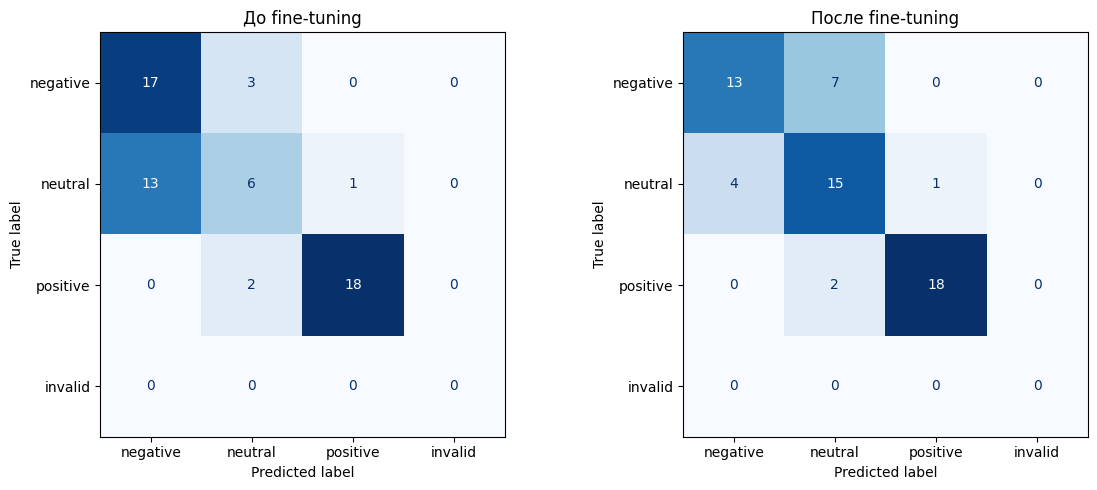

Примеры, где модель после обучения стала отвечать правильно:


,text,label_text,prediction_before,prediction_after
20,"качество вещи отличное, но доставка-ужас. сдел...",neutral,negative,neutral
21,Очень маленькая. На 44 максимум. Жидкая нить. ...,neutral,negative,neutral
23,"ну ниче так, но я даже в этой классной кофте в...",neutral,negative,neutral
25,"Шло достаточно долго, но ничего страшного. Пл...",neutral,negative,neutral
28,не дошел,neutral,negative,neutral
29,"куртка очень долго шла, качество неочень, ткан...",neutral,negative,neutral
30,"ммм дешевая ткань, немного торчат нитки, сшито...",neutral,negative,neutral
33,по размеру. М на 44 подошёл хорошо. Среднее ка...,neutral,negative,neutral
36,обычные треники из дешовой синтетики.,neutral,negative,neutral


Примеры, где после обучения ответ стал неправильным:


,text,label_text,prediction_before,prediction_after
2,"Жакет маленький, узок в рукавах и в груди.",negative,negative,neutral
6,"маломерит сильно, да и костюм так себе....носи...",negative,negative,neutral
13,"маломерка,может мне одной так не повезло...на ...",negative,negative,neutral
14,"Сама блузка нормальная, качество соответствует...",negative,negative,neutral


In [14]:
gold = test_sample["label_text"].tolist()
before_preds = [parse_answer(x) for x in baseline_generations]
after_preds = [parse_answer(x) for x in after_generations]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, preds, title in [
    (axes[0], before_preds, "До fine-tuning"),
    (axes[1], after_preds, "После fine-tuning"),
]:
    labels_for_cm = [p if p is not None else "invalid" for p in preds]
    cm = confusion_matrix(gold, labels_for_cm, labels=LABELS + ["invalid"])
    disp = ConfusionMatrixDisplay(cm, display_labels=LABELS + ["invalid"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.show()

predictions = test_sample[["text", "label_text"]].copy()
predictions["raw_before"] = baseline_generations
predictions["prediction_before"] = before_preds
predictions["raw_after"] = after_generations
predictions["prediction_after"] = after_preds
predictions["correct_before"] = predictions["prediction_before"] == predictions["label_text"]
predictions["correct_after"] = predictions["prediction_after"] == predictions["label_text"]

print("Примеры, где модель после обучения стала отвечать правильно:")
fixed = predictions[(~predictions.correct_before) & predictions.correct_after]
display(fixed[["text", "label_text", "prediction_before", "prediction_after"]].head(10))

print("Примеры, где после обучения ответ стал неправильным:")
regressed = predictions[predictions.correct_before & (~predictions.correct_after)]
display(regressed[["text", "label_text", "prediction_before", "prediction_after"]].head(10))

## 10. Сохранение артефактов

In [15]:
# Метрики и построчные предсказания можно скачать из файловой панели Colab.
comparison.to_json("metrics_before_after.json", orient="index", force_ascii=False, indent=2)
predictions.to_csv("predictions_before_after.csv", index=False)

print("Созданы файлы:")
print(" - metrics_before_after.json")
print(" - predictions_before_after.csv")
print(" -", OUTPUT_DIR, "(LoRA-адаптер и tokenizer)")

# Упакуем адаптер для скачивания одним файлом.
import shutil
adapter_archive = shutil.make_archive("qwen25_sentiment_lora", "zip", OUTPUT_DIR)
print("Архив адаптера:", adapter_archive)

Созданы файлы:
 - metrics_before_after.json
 - predictions_before_after.csv
 - /content/qwen25-sentiment-lora (LoRA-адаптер и tokenizer)
Архив адаптера: /content/qwen25_sentiment_lora.zip
